# Segmentación de clientes con RFM: Evaluación

Describir grupos de clientes a partir de recencia, frecuencia e importe de sus compras.

Silhouette, estabilidad entre dos semillas (ARI) y perfiles en unidades originales. Análisis descriptivo, sin validación predictiva ni nombres de negocio inventados.

Consulta la [metodología](../docs/metodologia.md). Los reportes corresponden a la última ejecución de cada etapa.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("customer_segmentation")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from customer_segmentation.alerts import configurar_notebook, mostrar_alertas
configurar_notebook()


# Segmentación de clientes con RFM: evaluacion

La segmentación es **similar** entre las dos semillas revisadas (ARI **0.9988**; corte descriptivo 0,8). La proyección de dos componentes conserva **93.87%** de la varianza. Los perfiles están expresados en las unidades originales. Los números de cluster no tienen significado ordinal ni equivalen a segmentos de negocio validados.


,cluster,recency,frequency,monetary,registros
0,0,17.7303,2.1900,556.8859,837
1,1,181.4929,1.3175,340.7382,1622
2,2,71.5331,4.0814,1801.8709,1167
3,3,12.1170,13.7626,8097.8016,712


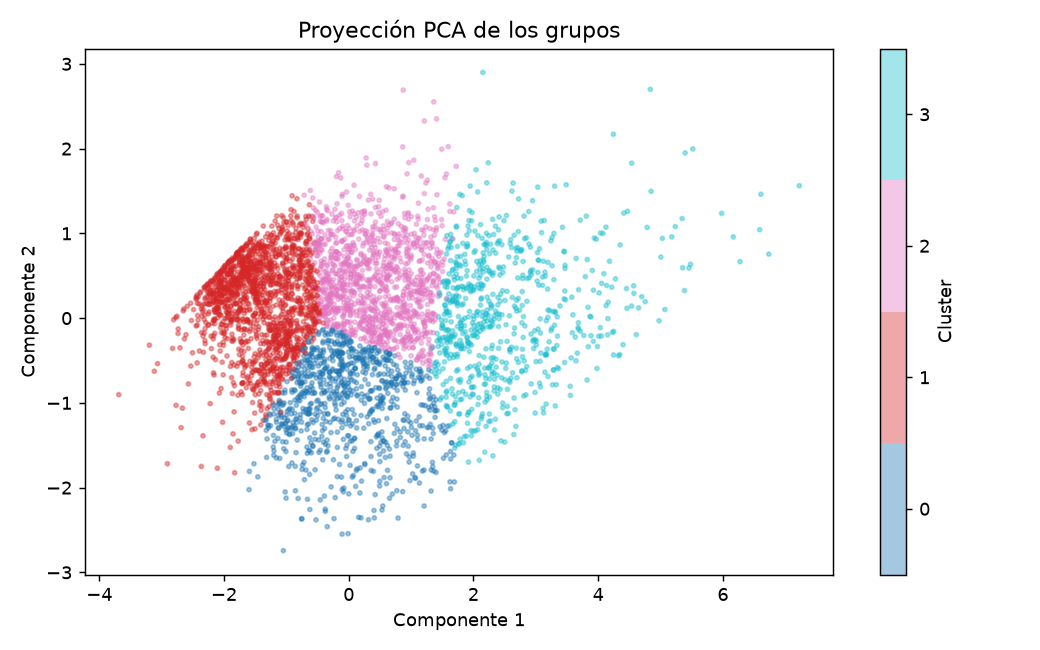

In [2]:
from customer_segmentation.flow import run_stage
metricas, comentario = run_stage(PROJECT_ROOT, "evaluacion")
display(Markdown(comentario))
from customer_segmentation.presentation import display_evaluation
display_evaluation(PROJECT_ROOT, metricas)


## Alertas

Avisos agrupados con descripción y acción sugerida. Los errores no se ocultan; no registrar warnings no garantiza que el análisis sea válido.

In [ ]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from customer_segmentation.informe import generar_informe
generar_informe(PROJECT_ROOT)
